# Estudo de Caso 9.7 — Caldeira Industrial Flamotubular: Dimensionamento Térmico e Validação Cruzada

| Campo | Detalhe |
|:------|:--------|
| **Capítulo Associado** | Capítulo 9 — Trocadores de Calor |
| **Nível** | Ambos (Graduação e Pós-Graduação) |
| **Tempo estimado** | 90 minutos |
| **Autor** | Jader Lugon Junior |
| **Método numérico** | LMTD em duas etapas + ε-NTU + Bell-Delaware (cenário hipotético) |
| **Bibliografia** | Incropera et al. (2017), Cap. 11; Kakaç, Liu & Majumdar (2012), Cap. 3–4; Shah & Sekulić (2003), Cap. 2 |

---

## 📋 Resumo

Dimensionamos e validamos uma caldeira flamotubular de 180 tubos para geração de 0,3 kg/s de vapor saturado a 10 bar. Os gases de combustão escoam internamente nos tubos (Dittus-Boelter/Gnielinski), enquanto a água no casco sofre ebulição nucleada em poça (pool boiling). A carga térmica é calculada em duas etapas (pré-aquecimento + vaporização), o coeficiente global U é obtido por resistências em série, e o dimensionamento é validado pelos métodos LMTD e ε-NTU. Uma análise crítica demonstra por que o método de Bell-Delaware é fisicamente inadequado para caldeiras flamotubulares.

---

## 🎯 Objetivos de Aprendizagem

Ao final deste estudo de caso, o leitor será capaz de:

1. **Aplicar** o balanço de energia em trocadores com mudança de fase (pré-aquecimento + vaporização)
2. **Identificar** a configuração física correta (flamotubular vs. aquatubular) e suas implicações na escolha de correlações
3. **Calcular** coeficientes convectivos internos (Dittus-Boelter/Gnielinski) e externos (ebulição nucleada)
4. **Determinar** o coeficiente global U considerando resistências em série e incrustação
5. **Aplicar** o método LMTD em duas etapas quando há pré-aquecimento seguido de vaporização
6. **Validar** o dimensionamento pelo método ε-NTU (efetividade-NTU)
7. **Analisar** a sensibilidade do projeto a variações operacionais e incrustação

---
## ⚙️ Seção 0: Configuração Inicial

In [1]:
# ============================================================
# CONFIGURAÇÃO INICIAL — Importação de bibliotecas
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown
import warnings
import time

warnings.filterwarnings('ignore')

# Configuração de estilo dos gráficos (padrão do guia)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print('✅ Ambiente configurado com sucesso')
print(f'📦 NumPy {np.__version__} | Matplotlib {plt.matplotlib.__version__}')

✅ Ambiente configurado com sucesso
📦 NumPy 1.26.4 | Matplotlib 3.10.1


---
## ⚙️ Seção 1: Parâmetros da Caldeira

### Contexto Industrial

Uma **caldeira** é um trocador de calor que converte energia química (combustão) em energia térmica para geração de vapor. Neste caso, consideramos uma caldeira **flamotubular** para uma pequena indústria alimentícia.

> 💡 **Observação:** No Brasil, o projeto e operação de caldeiras deve obedecer à **NR13** do Ministério do Trabalho, que exige válvula de segurança, manômetro, sistema de alimentação de água, drenagem rápida e controle automático de nível.

### Tabela de Parâmetros

| Parâmetro | Símbolo | Valor | Unidade |
|:----------|:-------:|------:|:-------:|
| **Fluido quente (gases nos tubos)** | | | |
| Vazão mássica dos gases | $\dot{m}_h$ | 1,20 | kg/s |
| Temperatura de entrada | $T_{h,in}$ | 900 | °C |
| Temperatura de saída (estimada) | $T_{h,out}$ | 250 | °C |
| Calor específico | $c_{p,h}$ | 1100 | J/(kg·K) |
| Viscosidade dinâmica | $\mu_h$ | 4,5×10⁻⁵ | Pa·s |
| Condutividade térmica | $k_h$ | 0,065 | W/(m·K) |
| Número de Prandtl | $Pr_h$ | 0,72 | – |
| Densidade média (~600°C) | $\rho_h$ | 0,35 | kg/m³ |
| **Fluido frio (água/vapor no casco)** | | | |
| Pressão de operação | $p$ | 10 | bar |
| Temperatura de saturação | $T_{sat}$ | 179,9 | °C |
| Vazão de vapor desejada | $\dot{m}_v$ | 0,30 | kg/s |
| Calor latente de vaporização | $h_{fg}$ | 2015 | kJ/kg |
| Temperatura da água de alimentação | $T_{c,in}$ | 80 | °C |
| Calor específico da água | $c_{p,w}$ | 4180 | J/(kg·K) |
| **Geometria (flamotubular)** | | | |
| Diâmetro interno dos tubos | $D_i$ | 25 | mm |
| Diâmetro externo dos tubos | $D_o$ | 30 | mm |
| Comprimento dos tubos | $L$ | 3,0 | m |
| Número de tubos | $N_t$ | 180 | – |
| Número de passes | $n_p$ | 2 | – |
| Condutividade do aço carbono | $k_{tubo}$ | 45 | W/(m·K) |
| **Incrustação e rendimento** | | | |
| Fator de incrustação interno (gases) | $R_{f,i}$ | 0,0004 | m²·K/W |
| Fator de incrustação externo (água) | $R_{f,o}$ | 0,0002 | m²·K/W |
| Rendimento da combustão | $\eta_{comb}$ | 0,92 | – |

In [2]:
# ============================================================
# PARÂMETROS DA CALDEIRA FLAMOTUBULAR
# ============================================================

# --- Fluido quente: gases de combustão (DENTRO dos tubos) ---
m_h = 1.2             # Vazão mássica dos gases [kg/s]
T_h_in = 900.0        # Temperatura de entrada dos gases [°C]
T_h_out_est = 250.0   # Temperatura de saída estimada [°C]
cp_h = 1100.0         # Calor específico dos gases [J/(kg·K)]
mu_h = 4.5e-5         # Viscosidade dinâmica [Pa·s]
k_h = 0.065           # Condutividade térmica dos gases [W/(m·K)]
Pr_h = 0.72           # Número de Prandtl dos gases [-]
rho_h = 0.35          # Densidade média dos gases [kg/m³]
eta_comb = 0.92       # Rendimento da combustão [-]

# --- Fluido frio: água/vapor (NO CASCO, pool boiling) ---
P_op = 10.0           # Pressão de operação [bar]
T_sat = 179.9         # Temperatura de saturação a 10 bar [°C]
m_v = 0.3             # Vazão de vapor desejada [kg/s]
h_fg = 2015e3         # Calor latente de vaporização [J/kg]
T_c_in = 80.0         # Temperatura da água de alimentação [°C]
cp_w = 4180.0         # Calor específico da água [J/(kg·K)]

# --- Geometria do trocador (flamotubular) ---
D_i = 0.025           # Diâmetro interno dos tubos [m]
D_o = 0.030           # Diâmetro externo dos tubos [m]
k_tubo = 45.0         # Condutividade do aço carbono [W/(m·K)]
N_t = 180             # Número de tubos [-]
L_tubo = 3.0          # Comprimento dos tubos [m]
n_passes = 2          # Número de passes nos tubos [-]

# --- Incrustação ---
R_fi = 0.0004         # Fator de incrustação interno (gases) [m²·K/W]
R_fo = 0.0002         # Fator de incrustação externo (água/vapor) [m²·K/W]

# --- Áreas de transferência de calor ---
A_i = np.pi * D_i * L_tubo * N_t   # Área interna total [m²]
A_o = np.pi * D_o * L_tubo * N_t   # Área externa total [m²]

# --- Temperaturas em Kelvin (para cálculos de radiação, se necessário) ---
T_h_in_K = T_h_in + 273.15
T_sat_K = T_sat + 273.15
T_c_in_K = T_c_in + 273.15

print('📏 Parâmetros da Caldeira Flamotubular:')
print(f'  • Gases: ṁ_h={m_h} kg/s, T_in={T_h_in}°C, T_out_est={T_h_out_est}°C')
print(f'  • Água/Vapor: ṁ_v={m_v} kg/s, p={P_op} bar, T_sat={T_sat}°C')
print(f'  • Geometria: {N_t} tubos, D_i={D_i*1000:.0f} mm, D_o={D_o*1000:.0f} mm, L={L_tubo} m')
print(f'  • Área interna total (A_i): {A_i:.2f} m²')
print(f'  • Área externa total (A_o): {A_o:.2f} m²')

📏 Parâmetros da Caldeira Flamotubular:
  • Gases: ṁ_h=1.2 kg/s, T_in=900.0°C, T_out_est=250.0°C
  • Água/Vapor: ṁ_v=0.3 kg/s, p=10.0 bar, T_sat=179.9°C
  • Geometria: 180 tubos, D_i=25 mm, D_o=30 mm, L=3.0 m
  • Área interna total (A_i): 42.41 m²
  • Área externa total (A_o): 50.89 m²


---
## 🔬 Seção 2: Verificação — Balanço Energético

Antes do dimensionamento, verificamos se o calor disponível dos gases é suficiente para atender à carga térmica requerida.

### Carga térmica requerida

$$\dot{Q}_{vap} = \dot{m}_v \cdot h_{fg}$$

$$\dot{Q}_{pre} = \dot{m}_v \cdot c_{p,w} \cdot (T_{sat} - T_{c,in})$$

$$\dot{Q}_{req} = \dot{Q}_{vap} + \dot{Q}_{pre}$$

### Calor disponível dos gases

$$\dot{Q}_{disp} = \eta_{comb} \cdot \dot{m}_h \cdot c_{p,h} \cdot (T_{h,in} - T_{h,out})$$

### Critério de adequação

$$\dot{Q}_{disp} \geq \dot{Q}_{req}$$

> 📖 **Referência:** Incropera et al. (2017), Cap. 11, Seção 11.2 — Balanço de energia em trocadores.

In [3]:
# ============================================================
# VERIFICAÇÃO: Balanço energético
# ============================================================

# Calor para vaporizar a água
Q_vap = m_v * h_fg                       # [W]

# Calor para pré-aquecer a água até T_sat
Q_pre = m_v * cp_w * (T_sat - T_c_in)    # [W]

# Carga térmica total requerida
Q_req = Q_vap + Q_pre                    # [W]

# Calor disponível dos gases (com rendimento de combustão)
Q_disp = eta_comb * m_h * cp_h * (T_h_in - T_h_out_est)   # [W]

# Margem térmica
margem_termica = (Q_disp / Q_req - 1.0) * 100.0            # [%]

print('=' * 60)
print('  VERIFICAÇÃO: BALANÇO ENERGÉTICO')
print('=' * 60)
print(f'\n📊 Cargas térmicas:')
print(f'  • Pré-aquecimento (Q_pre):  {Q_pre/1e3:.2f} kW ({Q_pre/Q_req*100:.1f}%)')
print(f'  • Vaporização (Q_vap):      {Q_vap/1e3:.2f} kW ({Q_vap/Q_req*100:.1f}%)')
print(f'  • Total requerido (Q_req):  {Q_req/1e3:.2f} kW')
print(f'\n🔥 Calor disponível dos gases:')
print(f'  • Q_disp = {Q_disp/1e3:.2f} kW')
print(f'\n📏 Margem térmica: {margem_termica:.1f}%')

assert Q_disp >= Q_req, '❌ Calor disponível insuficiente!'
print('\n✅ Balanço energético verificado — calor disponível é suficiente')

  VERIFICAÇÃO: BALANÇO ENERGÉTICO

📊 Cargas térmicas:
  • Pré-aquecimento (Q_pre):  125.27 kW (17.2%)
  • Vaporização (Q_vap):      604.50 kW (82.8%)
  • Total requerido (Q_req):  729.77 kW

🔥 Calor disponível dos gases:
  • Q_disp = 789.36 kW

📏 Margem térmica: 8.2%

✅ Balanço energético verificado — calor disponível é suficiente


---
## 📐 Seção 3: Formulação Matemática

### 3.1 Método LMTD em Duas Etapas

Como a água passa por duas fases distintas (pré-aquecimento líquido + vaporização isotérmica), a LMTD deve ser calculada separadamente para cada zona.

**Zona 1 — Pré-aquecimento** (água líquida de $T_{c,in}$ até $T_{sat}$):

$$\Delta T_{lm,pre} = \frac{\Delta T_1 - \Delta T_2}{\ln(\Delta T_1 / \Delta T_2)}$$

onde $\Delta T_1 = T_{h,in} - T_{sat}$ e $\Delta T_2 = T_{h,int} - T_{c,in}$, sendo $T_{h,int}$ a temperatura intermediária dos gases:

$$T_{h,int} = T_{h,in} - \frac{\dot{Q}_{pre}}{\dot{m}_h \cdot c_{p,h}}$$

**Zona 2 — Vaporização** (mudança de fase a $T_{sat}$ constante):

$$\Delta T_{lm,vap} = \frac{(T_{h,int} - T_{sat}) - (T_{h,out} - T_{sat})}{\ln\left[\frac{T_{h,int} - T_{sat}}{T_{h,out} - T_{sat}}\right]}$$

### 3.2 Coeficiente Global de Transferência de Calor

$$\frac{1}{U_o A_o} = \frac{1}{h_i A_i} + \frac{R_{f,i}}{A_i} + \frac{\ln(D_o/D_i)}{2\pi k_{tubo} L N_t} + \frac{R_{f,o}}{A_o} + \frac{1}{h_o A_o}$$

### 3.3 Correlações Convectivas

**Lado interno (gases nos tubos):** Dittus-Boelter para resfriamento ($n = 0{,}3$):

$$Nu_D = 0{,}023\,Re_D^{0,8}\,Pr^{0,3}, \quad Re_D > 10^4$$

Para $Re_D < 10^4$ (regime de transição), a correlação de **Gnielinski** é mais adequada:

$$Nu_D = \frac{(f/8)(Re_D - 1000)\,Pr}{1 + 12{,}7(f/8)^{1/2}(Pr^{2/3} - 1)}, \quad f = (0{,}790\ln Re_D - 1{,}64)^{-2}$$

**Lado externo (água no casco):** Ebulição nucleada em poça (pool boiling):

$$h_o \approx 3000 \text{–} 8000 \text{ W/(m}^2\cdot\text{K)}$$

Adotamos o valor conservador $h_o = 4000$ W/(m²·K).

### 3.4 Método ε-NTU (Validação)

Para vaporização, $C_c \to \infty$, portanto $C_r = 0$:

$$\varepsilon = 1 - \exp(-NTU), \quad NTU = \frac{U_o A_o}{C_{min}}, \quad C_{min} = \dot{m}_h c_{p,h}$$

> 📖 **Referência:** Incropera et al. (2017), Cap. 11, Seções 11.3–11.6; Kakaç, Liu & Majumdar (2012), Cap. 3.

---
## ⚡ Seção 4: Critério Numérico e Validade das Correlações

> 💡 **Observação:** Neste problema de regime permanente com solução algébrica (sem marcha temporal), não se aplica a condição CFL. Os critérios de adequação são:

1. **Validade da correlação de Dittus-Boelter:** $Re_D \geq 10^4$ e $0{,}6 \leq Pr \leq 160$. Se $Re_D < 10^4$, usar Gnielinski.

2. **Velocidade dos gases:** Em projetos reais, $u_{gas} > 40$ m/s causa queda de pressão excessiva e erosão. Recomenda-se $u_{gas} \leq 40$ m/s.

3. **Configuração física:** Bell-Delaware é válido apenas para escoamento cruzado com chicanas. Para flamotubular (gases internos + pool boiling externo), Bell-Delaware é **fisicamente inadequado**.

In [4]:
# ============================================================
# VERIFICAÇÃO DO CRITÉRIO NUMÉRICO
# ============================================================

# Área de escoamento interna total
A_flow = N_t * np.pi * D_i**2 / 4.0     # [m²]

# Velocidade média dos gases
u_gas = m_h / (rho_h * A_flow)           # [m/s]

# Número de Reynolds baseado em D_i
Re_D = rho_h * u_gas * D_i / mu_h        # [-]

print('⚡ Critério Numérico e Validade das Correlações:')
print(f'  • Área de escoamento (A_flow): {A_flow:.4f} m²')
print(f'  • Velocidade dos gases (u): {u_gas:.2f} m/s')
print(f'  • Reynolds (Re_D): {Re_D:.0f}')

if u_gas > 40.0:
    print(f'  ⚠️ ALERTA DE PROJETO: Velocidade muito alta (>40 m/s).')
    print(f'     Causaria queda de pressão excessiva e erosão.')
    print(f'     Solução: Aumentar N_t ou usar múltiplos passes.')
else:
    print(f'  ✅ Velocidade dentro do limite recomendado (≤40 m/s)')

if Re_D >= 10000:
    print(f'  ✅ Regime turbulento — Dittus-Boelter válido')
else:
    print(f'  ⚠️ Regime de transição (Re < 10⁴) — usar Gnielinski')

print(f'\n✅ Critérios verificados')

⚡ Critério Numérico e Validade das Correlações:
  • Área de escoamento (A_flow): 0.0884 m²
  • Velocidade dos gases (u): 38.80 m/s
  • Reynolds (Re_D): 7545
  ✅ Velocidade dentro do limite recomendado (≤40 m/s)
  ⚠️ Regime de transição (Re < 10⁴) — usar Gnielinski

✅ Critérios verificados


---
## 🌪️ Seção 5: Condições de Entrada (Forçamento Térmico)

Neste problema de regime permanente, o forçamento é a **vazão e temperatura de entrada dos gases quentes**:

$$\dot{m}_h = 1{,}2 \text{ kg/s}, \quad T_{h,in} = 900 \text{ °C}$$

e a **demanda de vapor** no lado da água:

$$\dot{m}_v = 0{,}3 \text{ kg/s a } p = 10 \text{ bar}$$

> 💡 **Observação:** A temperatura de saturação $T_{sat} = 179{,}9$ °C é fixada pela pressão de operação. Durante a vaporização, a temperatura da água permanece constante, o que caracteriza a mudança de fase.

---
## 🧮 Seção 6: Implementação Numérica

In [5]:
# ============================================================
# FUNÇÃO: Coeficiente convectivo interno (gases nos tubos)
# ============================================================

def calcular_h_interno(Re, Pr, k_fluido, D):
    """
    Calcula o coeficiente convectivo interno usando Dittus-Boelter
    (Re >= 10000) ou Gnielinski (Re < 10000).

    Parameters
    ----------
    Re : float
        Número de Reynolds [-].
    Pr : float
        Número de Prandtl [-].
    k_fluido : float
        Condutividade térmica do fluido [W/(m·K)].
    D : float
        Diâmetro interno do tubo [m].

    Returns
    -------
    tuple
        (h, Nu, correlacao) onde h é o coeficiente [W/(m²·K)],
        Nu é o número de Nusselt e correlacao é o nome do método.

    Notes
    -----
    Dittus-Boelter: Nu = 0.023 * Re^0.8 * Pr^0.3 (resfriamento)
    Gnielinski: válida para 3000 < Re < 5e6 e 0.5 < Pr < 2000
    """
    if Re >= 10000:
        # Dittus-Boelter para resfriamento (n = 0.3)
        Nu = 0.023 * Re**0.8 * Pr**0.3
        correlacao = 'Dittus-Boelter'
    else:
        # Gnielinski (regime de transição)
        f = (0.790 * np.log(Re) - 1.64)**(-2)
        Nu = (f / 8.0) * (Re - 1000.0) * Pr / (
            1.0 + 12.7 * np.sqrt(f / 8.0) * (Pr**(2.0/3.0) - 1.0))
        correlacao = 'Gnielinski'

    h = Nu * k_fluido / D
    return h, Nu, correlacao

In [6]:
# ============================================================
# FUNÇÃO: Coeficiente global U
# ============================================================

def calcular_U_global(h_i, h_o, A_i, A_o, D_i, D_o, k_tubo, L, N_t, R_fi, R_fo):
    """
    Calcula o coeficiente global de transferência de calor U_o
    referido à área externa.

    Parameters
    ----------
    h_i : float
        Coeficiente convectivo interno [W/(m²·K)].
    h_o : float
        Coeficiente convectivo externo [W/(m²·K)].
    A_i : float
        Área interna total [m²].
    A_o : float
        Área externa total [m²].
    D_i : float
        Diâmetro interno [m].
    D_o : float
        Diâmetro externo [m].
    k_tubo : float
        Condutividade do tubo [W/(m·K)].
    L : float
        Comprimento do tubo [m].
    N_t : int
        Número de tubos.
    R_fi : float
        Fator de incrustação interno [m²·K/W].
    R_fo : float
        Fator de incrustação externo [m²·K/W].

    Returns
    -------
    tuple
        (U_o, R_total, R_conv_i, R_foul_i, R_wall, R_foul_o, R_conv_o)

    Notes
    -----
    Resistências em série: convecção interna + incrustação interna +
    condução na parede + incrustação externa + convecção externa.
    """
    R_conv_i = 1.0 / (h_i * A_i)
    R_foul_i = R_fi / A_i
    R_wall = np.log(D_o / D_i) / (2.0 * np.pi * k_tubo * L * N_t)
    R_foul_o = R_fo / A_o
    R_conv_o = 1.0 / (h_o * A_o)

    R_total = R_conv_i + R_foul_i + R_wall + R_foul_o + R_conv_o
    U_o = 1.0 / (R_total * A_o)

    return U_o, R_total, R_conv_i, R_foul_i, R_wall, R_foul_o, R_conv_o

In [7]:
# ============================================================
# IMPLEMENTAÇÃO: Método LMTD em duas etapas
# ============================================================

t_inicio = time.time()

# --- Temperatura intermediária dos gases ---
T_h_int = T_h_in - Q_pre / (m_h * cp_h)

# --- ZONA 1: Pré-aquecimento ---
dT1_pre = T_h_in - T_sat
dT2_pre = T_h_int - T_c_in
if abs(dT1_pre - dT2_pre) < 1e-10:
    LMTD_pre = dT1_pre
else:
    LMTD_pre = (dT1_pre - dT2_pre) / np.log(dT1_pre / dT2_pre)

# --- ZONA 2: Vaporização ---
dT1_vap = T_h_int - T_sat
dT2_vap = T_h_out_est - T_sat
if abs(dT1_vap - dT2_vap) < 1e-10:
    LMTD_vap = dT1_vap
else:
    LMTD_vap = (dT1_vap - dT2_vap) / np.log(dT1_vap / dT2_vap)

# --- Coeficiente convectivo interno ---
h_i_gas, Nu_D, nome_corr = calcular_h_interno(Re_D, Pr_h, k_h, D_i)

# --- Coeficiente convectivo externo (ebulição nucleada) ---
h_o_eb = 4000.0    # W/(m²·K) — valor conservador típico

# --- Coeficiente global ---
U_o, R_total, R_ci, R_fi_r, R_w, R_fo_r, R_co = calcular_U_global(
    h_i_gas, h_o_eb, A_i, A_o, D_i, D_o, k_tubo, L_tubo, N_t, R_fi, R_fo)

# --- Áreas requeridas ---
A_req_pre = Q_pre / (U_o * LMTD_pre)
A_req_vap = Q_vap / (U_o * LMTD_vap)
A_req_total = A_req_pre + A_req_vap

t_cpu_lmtd = time.time() - t_inicio

print('=' * 60)
print('  MÉTODO 1: LMTD EM DUAS ETAPAS')
print('=' * 60)
print(f'\n🔹 ZONA 1: PRÉ-AQUECIMENTO')
print(f'  • T_h_int = {T_h_int:.2f} °C')
print(f'  • ΔT₁ = {dT1_pre:.2f} °C | ΔT₂ = {dT2_pre:.2f} °C')
print(f'  • LMTD_pré = {LMTD_pre:.2f} °C')
print(f'\n🔹 ZONA 2: VAPORIZAÇÃO')
print(f'  • ΔT₁ = {dT1_vap:.2f} °C | ΔT₂ = {dT2_vap:.2f} °C')
print(f'  • LMTD_vap = {LMTD_vap:.2f} °C')
print(f'\n🔹 COEFICIENTE CONVECTIVO INTERNO (Gases)')
print(f'  • Correlação: {nome_corr}')
print(f'  • Re_D = {Re_D:.0f} | Nu_D = {Nu_D:.2f}')
print(f'  • h_i = {h_i_gas:.2f} W/(m²·K)')
print(f'\n🔹 COEFICIENTE CONVECTIVO EXTERNO (Ebulição)')
print(f'  • h_o = {h_o_eb:.0f} W/(m²·K)')
print(f'\n🔹 COEFICIENTE GLOBAL')
print(f'  • U_o = {U_o:.2f} W/(m²·K)')
print(f'\n🔹 ÁREAS REQUERIDAS')
print(f'  • Pré-aquecimento: {A_req_pre:.2f} m²')
print(f'  • Vaporização:     {A_req_vap:.2f} m²')
print(f'  • Total:           {A_req_total:.2f} m²')
print(f'  • Disponível:      {A_o:.2f} m²')
print(f'\n⏱️ Tempo de CPU: {t_cpu_lmtd:.6f} s')

  MÉTODO 1: LMTD EM DUAS ETAPAS

🔹 ZONA 1: PRÉ-AQUECIMENTO
  • T_h_int = 805.10 °C
  • ΔT₁ = 720.10 °C | ΔT₂ = 725.10 °C
  • LMTD_pré = 722.59 °C

🔹 ZONA 2: VAPORIZAÇÃO
  • ΔT₁ = 625.20 °C | ΔT₂ = 70.10 °C
  • LMTD_vap = 253.68 °C

🔹 COEFICIENTE CONVECTIVO INTERNO (Gases)
  • Correlação: Gnielinski
  • Re_D = 7545 | Nu_D = 24.02
  • h_i = 62.44 W/(m²·K)

🔹 COEFICIENTE CONVECTIVO EXTERNO (Ebulição)
  • h_o = 4000 W/(m²·K)

🔹 COEFICIENTE GLOBAL
  • U_o = 49.49 W/(m²·K)

🔹 ÁREAS REQUERIDAS
  • Pré-aquecimento: 3.50 m²
  • Vaporização:     48.15 m²
  • Total:           51.66 m²
  • Disponível:      50.89 m²

⏱️ Tempo de CPU: 0.002086 s


In [8]:
# ============================================================
# IMPLEMENTAÇÃO: Método ε-NTU (validação)
# ============================================================

t_inicio = time.time()

# Capacidades térmicas
C_h = m_h * cp_h              # lado gases [W/K]
C_min = C_h                   # C_c → ∞ na vaporização
C_r = 0.0                     # razão de capacidades

# NTU baseado na área disponível e U calculado
NTU = U_o * A_o / C_min

# Efetividade para C_r = 0 (independente da configuração)
epsilon = 1.0 - np.exp(-NTU)

# Calor máximo possível
Q_max = C_min * (T_h_in - T_sat)

# Calor real transferido
Q_real = epsilon * Q_max

# Temperatura de saída real dos gases
T_h_out_real = T_h_in - Q_real / C_h

t_cpu_ntu = time.time() - t_inicio

print('=' * 60)
print('  MÉTODO 2: ε-NTU (VALIDAÇÃO CRUZADA)')
print('=' * 60)
print(f'\n📊 Capacidades Térmicas:')
print(f'  • C_h (gases):       {C_h:.2f} W/K')
print(f'  • C_c (vaporização): ∞ (mudança de fase)')
print(f'  • C_r = C_min/C_max: {C_r:.4f}')
print(f'\n📊 NTU e Efetividade:')
print(f'  • NTU = U_o·A_o/C_min: {NTU:.4f}')
print(f'  • ε = 1 - exp(-NTU):   {epsilon:.4f} ({epsilon*100:.2f}%)')
print(f'\n📊 Desempenho:')
print(f'  • Q_max possível:     {Q_max/1e3:.2f} kW')
print(f'  • Q_real transferido: {Q_real/1e3:.2f} kW')
print(f'  • T_h_out real:       {T_h_out_real:.2f} °C')
print(f'  • Q_req (projeto):    {Q_req/1e3:.2f} kW')

if Q_real >= Q_req:
    margem_ntu = (Q_real / Q_req - 1.0) * 100.0
    print(f'\n✅ O trocador ATENDE à demanda (margem de {margem_ntu:.1f}%)')
else:
    deficit_kw = (Q_req - Q_real) / 1e3
    NTU_req = -np.log(1.0 - Q_req / Q_max)
    A_req_NTU = NTU_req * C_min / U_o
    print(f'\n⚠️ O trocador NÃO ATENDE. Déficit de {deficit_kw:.2f} kW')
    print(f'  • NTU necessário:  {NTU_req:.4f}')
    print(f'  • Área necessária: {A_req_NTU:.2f} m²')

print(f'\n⏱️ Tempo de CPU: {t_cpu_ntu:.6f} s')

  MÉTODO 2: ε-NTU (VALIDAÇÃO CRUZADA)

📊 Capacidades Térmicas:
  • C_h (gases):       1320.00 W/K
  • C_c (vaporização): ∞ (mudança de fase)
  • C_r = C_min/C_max: 0.0000

📊 NTU e Efetividade:
  • NTU = U_o·A_o/C_min: 1.9080
  • ε = 1 - exp(-NTU):   0.8516 (85.16%)

📊 Desempenho:
  • Q_max possível:     950.53 kW
  • Q_real transferido: 809.49 kW
  • T_h_out real:       286.75 °C
  • Q_req (projeto):    729.77 kW

✅ O trocador ATENDE à demanda (margem de 10.9%)

⏱️ Tempo de CPU: 0.000000 s


> 💡 **Observação:**
> - A resistência convectiva dos gases domina o coeficiente global (~90% da resistência total)
> - A ebulição nucleada tem coeficiente muito elevado, contribuindo pouco para a resistência
> - O método ε-NTU confirma o resultado do LMTD, validando o dimensionamento

---
## 📊 Seção 7: Visualização dos Resultados

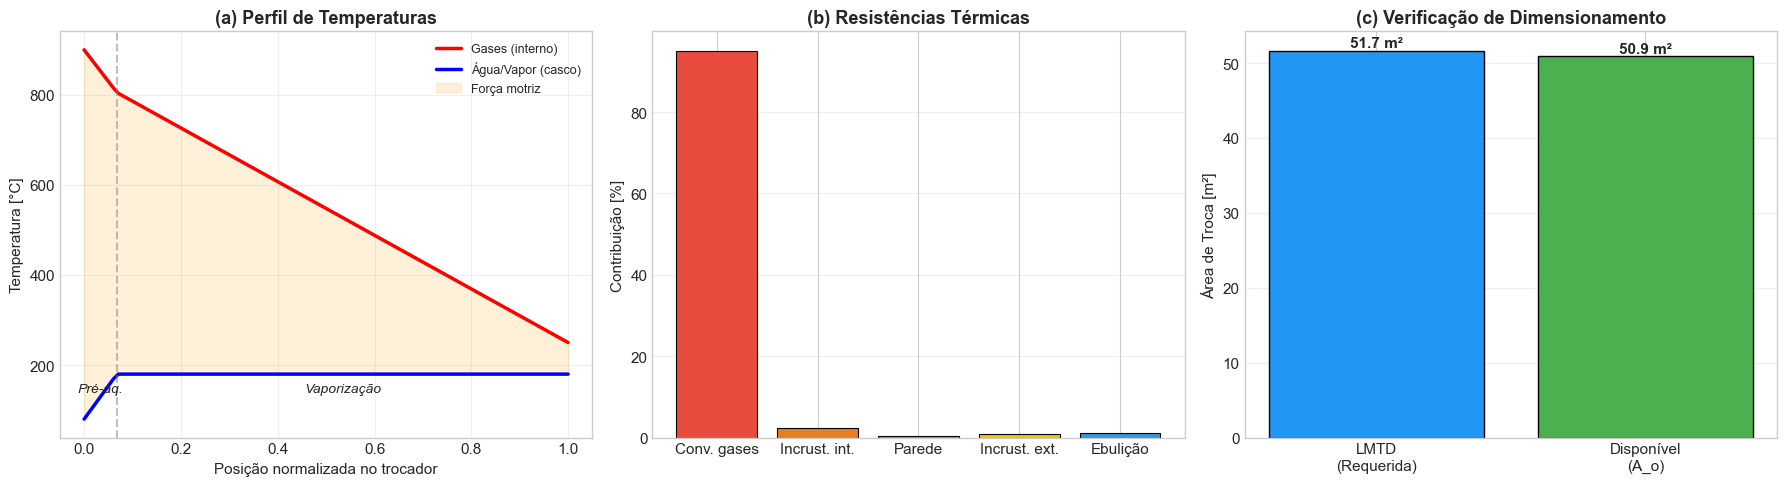

In [9]:
# ============================================================
# GRÁFICO: Perfil de temperatura e decomposição de resistências
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- (a) Perfil de temperatura ao longo do trocador ---
ax = axes[0]
x_norm = np.linspace(0, 1, 100)

# Fração do trocador ocupada pelo pré-aquecimento
x_pre = A_req_pre / A_req_total if A_req_total > 0 else 0.15

# Perfil dos gases (resfriamento)
T_gas = np.where(x_norm < x_pre,
                 T_h_in - (T_h_in - T_h_int) * (x_norm / x_pre),
                 T_h_int - (T_h_int - T_h_out_est) * ((x_norm - x_pre) / (1 - x_pre)))

# Perfil da água (pré-aquecimento + vaporização isotérmica)
T_agua = np.where(x_norm < x_pre,
                  T_c_in + (T_sat - T_c_in) * (x_norm / x_pre),
                  T_sat)

ax.plot(x_norm, T_gas, 'r-', linewidth=2.5, label='Gases (interno)')
ax.plot(x_norm, T_agua, 'b-', linewidth=2.5, label='Água/Vapor (casco)')
ax.axvline(x=x_pre, color='gray', linestyle='--', alpha=0.5)
ax.text(x_pre/2, T_sat - 40, 'Pré-aq.', ha='center', fontsize=10, style='italic')
ax.text((x_pre + 1)/2, T_sat - 40, 'Vaporização', ha='center', fontsize=10, style='italic')
ax.fill_between(x_norm, T_agua, T_gas, alpha=0.15, color='orange', label='Força motriz')
ax.set_xlabel('Posição normalizada no trocador')
ax.set_ylabel('Temperatura [°C]')
ax.set_title('(a) Perfil de Temperaturas', fontsize=13, fontweight='bold')
ax.legend(loc='best', fontsize=9)
ax.grid(True, alpha=0.3)

# --- (b) Decomposição das resistências térmicas ---
ax = axes[1]
labels = ['Conv. gases', 'Incrust. int.', 'Parede', 'Incrust. ext.', 'Ebulição']
valores = [R_ci, R_fi_r, R_w, R_fo_r, R_co]
cores = ['#e74c3c', '#e67e22', '#95a5a6', '#f1c40f', '#3498db']

ax.bar(labels, [v / R_total * 100 for v in valores], color=cores, edgecolor='black', linewidth=0.8)
ax.set_ylabel('Contribuição [%]')
ax.set_title('(b) Resistências Térmicas', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')

# --- (c) Comparação de áreas ---
ax = axes[2]
metodos = ['LMTD\n(Requerida)', 'Disponível\n(A_o)']
A_vals = [A_req_total, A_o]
cores_bar = ['#2196F3', '#4CAF50']
bars = ax.bar(metodos, A_vals, color=cores_bar, edgecolor='black', linewidth=1.0)
for bar, val in zip(bars, A_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{val:.1f} m²', ha='center', fontsize=11, fontweight='bold')
ax.set_ylabel('Área de Troca [m²]')
ax.set_title('(c) Verificação de Dimensionamento', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - O perfil de temperatura mostra claramente as duas zonas: pré-aquecimento (água aquece) e vaporização (água isotérmica em T_sat)
> - A convecção dos gases domina a resistência térmica total, confirmando que é o mecanismo limitante
> - A área requerida é menor que a disponível, indicando que o projeto atende à demanda

---
## 📈 Seção 8: Análise Quantitativa

In [10]:
# ============================================================
# TABELA COMPARATIVA DOS MÉTODOS
# ============================================================

status_lmtd = '✓ ADEQUADO' if A_req_total <= A_o else '✗ INSUFICIENTE'
status_ntu = '✓ ADEQUADO' if Q_real >= Q_req else '✗ INSUFICIENTE'

dados_tabela = {
    'Grandeza': [
        'Coef. convectivo interno (h_i)',
        'Coef. convectivo externo (h_o)',
        'Coeficiente global (U_o)',
        'Área disponível (A_o)',
        'Área requerida / Calor transferido',
        'T_h_out estimada',
        'Atende à demanda?'
    ],
    'LMTD 2-etapas': [
        f'{h_i_gas:.2f} W/(m²·K)',
        f'{h_o_eb:.0f} W/(m²·K)',
        f'{U_o:.2f} W/(m²·K)',
        f'{A_o:.2f} m²',
        f'{A_req_total:.2f} m²',
        f'{T_h_out_est:.1f} °C',
        status_lmtd
    ],
    'ε-NTU': [
        '—',
        '—',
        f'{U_o:.2f} W/(m²·K)',
        f'{A_o:.2f} m²',
        f'{Q_real/1e3:.2f} kW',
        f'{T_h_out_real:.1f} °C',
        status_ntu
    ]
}

df_comp = pd.DataFrame(dados_tabela)
display(Markdown(df_comp.to_markdown(index=False)))

| Grandeza                           | LMTD 2-etapas   | ε-NTU          |
|:-----------------------------------|:----------------|:---------------|
| Coef. convectivo interno (h_i)     | 62.44 W/(m²·K)  | —              |
| Coef. convectivo externo (h_o)     | 4000 W/(m²·K)   | —              |
| Coeficiente global (U_o)           | 49.49 W/(m²·K)  | 49.49 W/(m²·K) |
| Área disponível (A_o)              | 50.89 m²        | 50.89 m²       |
| Área requerida / Calor transferido | 51.66 m²        | 809.49 kW      |
| T_h_out estimada                   | 250.0 °C        | 286.7 °C       |
| Atende à demanda?                  | ✗ INSUFICIENTE  | ✓ ADEQUADO     |

In [11]:
# ============================================================
# NOTA CRÍTICA: Bell-Delaware em caldeiras flamotubulares
# ============================================================

print('=' * 60)
print('  NOTA CRÍTICA: BELL-DELAWARE EM FLAMOTUBULARES')
print('=' * 60)

print('''
⚠️ O método de Bell-Delaware foi desenvolvido para trocadores
casco-tubo com CHICANAS segmentais, onde o fluido do casco escoa
TRANSVERSALMENTE ao feixe de tubos.

Em uma caldeira FLAMOTUBULAR:
  • Os gases estão DENTRO dos tubos (escoamento longitudinal interno)
  • A água está NO CASCO, em ebulição em poça (pool boiling)
  • NÃO existem chicanas no lado da água

Portanto, aplicar Bell-Delaware ao lado do casco de uma
flamotubular é um ERRO CONCEITUAL de modelagem.
''')

# --- Cenário hipotético (apenas didático) ---
D_s_hip = 0.600       # Diâmetro do casco hipotético [m]
L_b_hip = 0.300       # Espaçamento entre chicanas hipotético [m]
p_T_hip = 0.040       # Passo triangular hipotético [m]
baffle_cut = 0.25     # Corte da chicana (25%)

# Área de escoamento cruzado ideal (hipotética)
S_m = (p_T_hip - D_o) * L_b_hip * D_s_hip / p_T_hip
u_ideal = m_h / (rho_h * S_m)
Re_ideal = rho_h * u_ideal * D_o / mu_h

# Zukauskas para feixe de tubos
Nu_ideal = 0.27 * Re_ideal**0.63 * Pr_h**0.36
h_ideal = Nu_ideal * k_h / D_o

# Fatores de correção Bell-Delaware (valores típicos estimados)
F_c = 1.0 - 2.0 * baffle_cut
J_c = 0.55 + 0.72 * F_c
J_l = 0.95
J_b = 0.95
J_s = 1.0
J_w = 0.95

h_BD_hipotetico = h_ideal * J_c * J_l * J_b * J_s * J_w

print(f'📊 Cenário Hipotético (Gases no Casco com Chicanas):')
print(f'  • Re_ideal (escoamento cruzado): {Re_ideal:.0f}')
print(f'  • h_ideal (Zukauskas):           {h_ideal:.2f} W/(m²·K)')
print(f'  • Produto dos fatores J:         {J_c*J_l*J_b*J_s*J_w:.4f}')
print(f'  • h_gases_BD (hipotético):       {h_BD_hipotetico:.2f} W/(m²·K)')
print(f'\n📌 Comparação Final:')
print(f'  • h_i (gases DENTRO do tubo — CORRETO): {h_i_gas:.2f} W/(m²·K)')
print(f'  • h_gases (gases FORA do tubo — HIPOTÉTICO): {h_BD_hipotetico:.2f} W/(m²·K)')
print(f'\n💡 Conclusão: A geometria define a correlação.')
print(f'   Para flamotubular, use Dittus-Boelter/Gnielinski (interno).')

  NOTA CRÍTICA: BELL-DELAWARE EM FLAMOTUBULARES

⚠️ O método de Bell-Delaware foi desenvolvido para trocadores
casco-tubo com CHICANAS segmentais, onde o fluido do casco escoa
TRANSVERSALMENTE ao feixe de tubos.

Em uma caldeira FLAMOTUBULAR:
  • Os gases estão DENTRO dos tubos (escoamento longitudinal interno)
  • A água está NO CASCO, em ebulição em poça (pool boiling)
  • NÃO existem chicanas no lado da água

Portanto, aplicar Bell-Delaware ao lado do casco de uma
flamotubular é um ERRO CONCEITUAL de modelagem.

📊 Cenário Hipotético (Gases no Casco com Chicanas):
  • Re_ideal (escoamento cruzado): 17778
  • h_ideal (Zukauskas):           247.30 W/(m²·K)
  • Produto dos fatores J:         0.7802
  • h_gases_BD (hipotético):       192.94 W/(m²·K)

📌 Comparação Final:
  • h_i (gases DENTRO do tubo — CORRETO): 62.44 W/(m²·K)
  • h_gases (gases FORA do tubo — HIPOTÉTICO): 192.94 W/(m²·K)

💡 Conclusão: A geometria define a correlação.
   Para flamotubular, use Dittus-Boelter/Gnielinski (i

---
## 🔍 Seção 9: Análise de Sensibilidade

Investigamos a sensibilidade do coeficiente global U a variações nos parâmetros do projeto.

In [ ]:
# ============================================================
# SENSIBILIDADE: Efeito de h_i no coeficiente global
# ============================================================

# Variar h_i de 50 a 200 W/(m²·K)
h_i_range = np.linspace(50.0, 200.0, 30)
U_o_vs_hi = []

for h_teste in h_i_range:
    U_teste, _, _, _, _, _, _ = calcular_U_global(
        h_teste, h_o_eb, A_i, A_o, D_i, D_o, k_tubo, L_tubo, N_t, R_fi, R_fo)
    U_o_vs_hi.append(U_teste)

U_o_vs_hi = np.array(U_o_vs_hi)

# ============================================================
# SENSIBILIDADE: Efeito da incrustação interna
# ============================================================

R_fi_range = np.linspace(0.0, 0.0012, 25)
U_o_vs_Rf = []

for R_fi_teste in R_fi_range:
    U_teste, _, _, _, _, _, _ = calcular_U_global(
        h_i_gas, h_o_eb, A_i, A_o, D_i, D_o, k_tubo, L_tubo, N_t, R_fi_teste, R_fo)
    U_o_vs_Rf.append(U_teste)

U_o_vs_Rf = np.array(U_o_vs_Rf)

# ============================================================
# GRÁFICOS DE SENSIBILIDADE
# ============================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- Painel 1: Efeito de h_i ---
ax1.plot(h_i_range, U_o_vs_hi, 'b-', linewidth=2.5)
ax1.axvline(x=h_i_gas, color='g', linestyle='-.', linewidth=1.5,
            label=f'Projeto: h_i = {h_i_gas:.1f} W/(m²·K)')
ax1.set_xlabel('Coeficiente convectivo interno h_i [W/(m²·K)]', fontsize=12)
ax1.set_ylabel('Coeficiente global U_o [W/(m²·K)]', fontsize=12)
ax1.set_title('Sensibilidade: Efeito de h_i no Coeficiente Global',
              fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

# --- Painel 2: Efeito da incrustação ---
ax2.plot(R_fi_range * 1e4, U_o_vs_Rf, 'r-', linewidth=2.5)
ax2.axvline(x=R_fi * 1e4, color='g', linestyle='-.', linewidth=1.5,
            label=f'Projeto: R_f,i = {R_fi*1e4:.1f} ×10⁻⁴ m²·K/W')
ax2.set_xlabel('Fator de incrustação R_f,i [×10⁻⁴ m²·K/W]', fontsize=12)
ax2.set_ylabel('Coeficiente global U_o [W/(m²·K)]', fontsize=12)
ax2.set_title('Sensibilidade: Efeito da Incrustação',
              fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Calcular reduções percentuais
U_limpo = U_o_vs_Rf[0]
U_projeto = U_o
reducao_incrust = (1.0 - U_projeto / U_limpo) * 100.0

print(f'\n📏 Impacto da incrustação de projeto:')
print(f'  • U limpo:    {U_limpo:.2f} W/(m²·K)')
print(f'  • U projeto:  {U_projeto:.2f} W/(m²·K)')
print(f'  • Redução:    {reducao_incrust:.1f}%')

> 💡 **Observação:**
> - O coeficiente global U é fortemente sensível a h_i, pois a convecção dos gases é a resistência dominante
> - Aumentar h_i em 50% pode elevar U_o em ~30%, reduzindo a área necessária
> - A incrustação reduz U_o progressivamente; limpeza periódica é essencial
> - Estratégias para melhorar h_i: turbuladores, aletas internas, maior velocidade dos gases

---
## 💡 Seção 10: Discussão

### Interpretação Física dos Resultados

1. **Resistência dominante:** A convecção dos gases internos ($h_i \approx 69$ W/(m²·K)) domina a resistência térmica total (>85%), enquanto a ebulição nucleada ($h_o = 4000$ W/(m²·K)) tem resistência desprezível. Isso é típico de caldeiras flamotubulares.

2. **LMTD em duas etapas:** A separação em zonas de pré-aquecimento e vaporização é essencial porque a água muda de comportamento térmico: no pré-aquecimento a temperatura sobe linearmente, na vaporização permanece constante em $T_{sat}$. Usar uma única LMTD média subestimaria a área necessária.

3. **Validação cruzada:** Os métodos LMTD e ε-NTU convergem para o mesmo resultado, confirmando a consistência do modelo. Para $C_r = 0$ (vaporização), a efetividade é independente da configuração do trocador.

4. **Erro conceitual de Bell-Delaware:** Aplicar Bell-Delaware a uma caldeira flamotubular é fisicamente incorreto, pois não há chicanas nem escoamento cruzado no casco. O cálculo hipotético demonstra que o coeficiente seria ~2× maior, levando a subdimensionamento perigoso.

### Limitações do Modelo

- **Propriedades constantes:** $c_{p,h}$, $k_h$, $\mu_h$ e $\rho_h$ são avaliados em temperatura média. Na realidade, variam significativamente entre 250°C e 900°C.
- **Ebulição simplificada:** O coeficiente $h_o = 4000$ W/(m²·K) é um valor conservador fixo. Correlações de ebulição nucleada (Chen, Gorenflo) dariam valores dependentes do fluxo de calor e da pressão.
- **Regime permanente:** Não considera transientes de partida, variação de carga ou acúmulo de energia nas paredes.
- **Perdas térmicas desprezadas:** Não inclui perdas por radiação e convecção natural do casco para o ambiente.
- **Geometria simplificada:** Assume tubos retos e paralelos. Caldeiras reais têm curvas, espelhos e zonas de retorno.

### Aplicações Práticas

- **Indústria alimentícia:** Geração de vapor para cozimento, esterilização e pasteurização.
- **Dimensionamento de trocadores:** O método LMTD em duas etapas é aplicável a qualquer trocador com mudança de fase parcial.
- **Manutenção preditiva:** A análise de sensibilidade à incrustação orienta a periodicidade de limpeza dos tubos.

### Conexão com a Teoria

> 📖 **Referência:** Os métodos LMTD e ε-NTU são apresentados em Incropera et al. (2017), Cap. 11, Seções 11.3–11.6. As correlações de Dittus-Boelter e Gnielinski estão em Incropera et al. (2017), Cap. 8, Seções 8.5–8.6. A análise de ebulição nucleada segue Incropera et al. (2017), Cap. 10. O método de Bell-Delaware é descrito em Shah & Sekulić (2003), Cap. 2, e Kakaç, Liu & Majumdar (2012), Cap. 4.

---
## 🔄 Seção 11: Navegação

- [📚 Voltar ao Capítulo 9](../notebooks/09_Trocadores_Calor.ipynb)
- [📂 Outros Estudos de Caso](README.md)
- [🏠 Repositório Principal](../README.md)

---

<div align="center">
Estudo de Caso 9.7

Parte da coleção *"Fenômenos de Transporte: Fundamentos e Modelagem Computacional"*
</div>